# **Antimicrobial Resistance Genes in *Klebsiella pneumoniae* across Sub-Saharan Africa**

## **Descriptive and Diagnostic Analysis**

**Data source:** NCBI Pathogen Detection (AMRFinderPlus results), sub-Saharan African isolates.

**Unit of analysis:** one sequenced *K. pneumoniae* isolate.

**Outcome:** carriage of acquired resistance genes, summarised as ESBL/AmpC genes, carbapenemase genes, colistin resistance determinants and the number of antibiotic classes affected (MDR genotype = 3 or more classes).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/data-visualization/klebsiella-amr')
except ImportError:
    BASE = Path('.')

RAW = BASE / 'data' / 'raw'
PROCESSED = BASE / 'data' / 'processed'
FIGURES = BASE / 'figures'
TABLES = BASE / 'tables'
for folder in [PROCESSED, FIGURES, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#b8b7b3'
BLUES = LinearSegmentedColormap.from_list('blues', ['#f4f8fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8984',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'center',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'legend.frameon': False,
})

def save(fig, name):
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')

def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

# **1.0 EXPLORATORY DATA ANALYSIS**

### 1.1 Overview of the dataset

In [2]:
df = pd.read_csv(RAW / 'klebsiella_ssa_ncbi.tsv', sep='\t', dtype=str, na_values=['NULL', ''])
catalog = pd.read_csv(RAW / 'ReferenceGeneCatalog.txt', sep='\t', dtype=str)

print(f"Isolates: {len(df):,}   Columns: {df.shape[1]}")
df.head(3)

Isolates: 10,441   Columns: 12


,target_acc,biosample_acc,bioproject_acc,scientific_name,geo_loc_name,collection_date,isolation_source,host,epi_type,number_amr_genes,AMR_genotypes,AST_phenotypes
0,PDT000088802.2,SAMN04011419,PRJNA287968,Klebsiella pneumoniae subsp. pneumoniae,South Africa: Durban,NaN,NaN,Homo sapiens,clinical,25,"aac(3)-IIe,aac(6')-Ib-cr5,aph(3'')-Ib,aph(6)-I...",NaN
1,PDT000088806.3,SAMN04011426,PRJNA287968,Klebsiella pneumoniae subsp. pneumoniae,South Africa: Durban,NaN,NaN,Homo sapiens,clinical,25,"aac(3)-IIe,aac(6')-Ib-cr5,aph(3'')-Ib,aph(6)-I...",NaN
2,PDT000088809.2,SAMN04011433,PRJNA287968,Klebsiella pneumoniae subsp. pneumoniae,South Africa: Durban,2013-07-03,blood,Homo sapiens,clinical,24,"aac(3)-IIe,aac(6')-Ib-cr5,aph(3'')-Ib,aph(6)-I...",NaN


### 1.2 Missingness and duplicates

In [3]:
missing = pd.DataFrame({'Missing': df.isna().sum(), 'Missing %': (df.isna().mean() * 100).round(1)})
display(missing)

print(f"Duplicate isolates (target_acc): {df['target_acc'].duplicated().sum()}")
print(f"Duplicate biosamples:            {df['biosample_acc'].duplicated().sum()}")

placeholders = ['missing', 'not collected', 'not applicable', 'unknown', 'not provided', 'na', 'n/a', 'none']
hidden = df[['collection_date', 'isolation_source', 'host']].apply(lambda s: s.str.lower().str.strip().isin(placeholders).sum())
print("\nPlaceholder text that also means missing:")
print(hidden)

,Missing,Missing %
target_acc,0,0.0
biosample_acc,0,0.0
bioproject_acc,0,0.0
scientific_name,0,0.0
geo_loc_name,0,0.0
collection_date,738,7.1
isolation_source,3847,36.8
host,3224,30.9
epi_type,2797,26.8
number_amr_genes,0,0.0


Duplicate isolates (target_acc): 0
Duplicate biosamples:            0

Placeholder text that also means missing:
collection_date     1451
isolation_source       1
host                   1
dtype: int64


**Handling missing data:**

- There are no duplicate isolates or biosamples.
- Some fields use text such as "missing" instead of being left blank, so they are missing more often than the table shows. These are treated as missing.
- Missing values are not imputed. Isolates with no specimen are kept as "Not recorded", and analyses by year use only isolates with a recorded year.
- Lab susceptibility results (`AST_phenotypes`) are almost entirely missing, so resistance is measured from genes (`AMR_genotypes`), which are complete.
- How missing year and specimen are spread across countries, and whether they relate to resistance, is checked in section 1.7.

### 1.3 Keep *Klebsiella pneumoniae* only

In [4]:
print(df['scientific_name'].value_counts())

df = df[df['scientific_name'].str.startswith('Klebsiella pneumoniae')].copy()
print(f"\nK. pneumoniae isolates kept: {len(df):,}")
print(f"Isolates with lab susceptibility results: {df['AST_phenotypes'].notna().sum():,} ({df['AST_phenotypes'].notna().mean() * 100:.1f}%)")

scientific_name
Klebsiella pneumoniae                                         9393
Klebsiella pneumoniae subsp. pneumoniae CIP 52.145 = B5055     281
Klebsiella variicola                                           268
Klebsiella quasipneumoniae                                     135
Klebsiella quasipneumoniae subsp. similipneumoniae             131
Klebsiella variicola subsp. variicola                           88
Klebsiella pneumoniae subsp. pneumoniae                         87
Klebsiella quasipneumoniae subsp. quasipneumoniae               32
Klebsiella aerogenes                                            22
Klebsiella variicola subsp. tropica                              4
Name: count, dtype: int64

K. pneumoniae isolates kept: 9,761
Isolates with lab susceptibility results: 108 (1.1%)


**Why:** the file also contains 680 isolates of closely related species (*K. variicola*, *K. quasipneumoniae*, *K. aerogenes*). They are different organisms with their own chromosomal genes, and the gene rules in section 1.6 are built for *K. pneumoniae*, so only the three *K. pneumoniae* names are kept.

### 1.4 Country, region and collection year

Countries are grouped into the African Union regions used by Africa CDC.

In [5]:
# 1.4.1 Country and African region
df['country'] = df['geo_loc_name'].str.split(':').str[0].str.strip()
print(sorted(df['country'].unique()))

regions = {
    'Eastern Africa': ['Uganda', 'Kenya', 'Tanzania', 'Rwanda', 'Ethiopia', 'Somalia', 'South Sudan', 'Sudan', 'Eritrea',
                       'Djibouti', 'Madagascar', 'Mauritius', 'Comoros', 'Seychelles'],
    'Southern Africa': ['South Africa', 'Botswana', 'Namibia', 'Lesotho', 'Eswatini', 'Malawi', 'Mozambique', 'Zambia',
                        'Zimbabwe', 'Angola'],
    'Western Africa': ['Nigeria', 'Ghana', 'Senegal', 'Gambia', 'Mali', 'Burkina Faso', 'Niger', 'Benin', 'Togo', 'Guinea',
                       'Guinea-Bissau', 'Sierra Leone', 'Liberia', "Côte d'Ivoire", 'Cabo Verde'],
    'Central Africa': ['Cameroon', 'Gabon', 'Democratic Republic of the Congo', 'Congo', 'Central African Republic',
                       'Chad', 'Equatorial Guinea', 'Burundi', 'Sao Tome and Principe'],
}
region_map = {country: region for region, countries in regions.items() for country in countries}
df['region'] = df['country'].map(region_map)
print(f"\nIsolates without a region: {df['region'].isna().sum()}")
print(df['region'].value_counts())

['Benin', 'Botswana', 'Burkina Faso', 'Cameroon', 'Central African Republic', 'Ethiopia', 'Gambia', 'Ghana', 'Guinea', 'Kenya', 'Madagascar', 'Malawi', 'Mali', 'Mozambique', 'Namibia', 'Niger', 'Nigeria', 'Rwanda', 'Senegal', 'South Africa', 'Sudan', 'Tanzania', 'Togo', 'Uganda', 'Zambia']

Isolates without a region: 0
region
Southern Africa    5210
Eastern Africa     2941
Western Africa     1546
Central Africa       64
Name: count, dtype: int64


In [6]:
# 1.4.2 Collection year
df['year'] = pd.to_numeric(df['collection_date'].str.extract(r'(\d{4})')[0], errors='coerce')
print(df['year'].value_counts().sort_index().head(5))
display(df.loc[df['year'] < 2000, ['target_acc', 'country', 'collection_date', 'isolation_source', 'AMR_genotypes']])

year
1905.0     1
2001.0    30
2002.0    23
2009.0     7
2010.0    27
Name: count, dtype: int64


,target_acc,country,collection_date,isolation_source,AMR_genotypes
3746,PDT002019018.1,Kenya,1905-07-13,wastewater,"aac(6')-Ib-cr5,aadA1,aadA2,aph(3'')-Ib,aph(6)-..."


**Why one year is set to missing:** the earliest year is 1905, followed by a jump to 2001. The 1905 isolate is from Kenyan wastewater and carries *blaNDM-5*, *blaOXA-232* and *armA*. These genes were first described in the 2000s and 2010s, and carbapenems only came into use in the 1980s, so a 1905 collection date is impossible and is almost certainly a typing error. Because the true year is unknown, it is set to missing rather than corrected. Years before 1990 are treated as impossible. This is a lenient cut-off that would still keep genuine archived isolates from the 1990s.

In [7]:
# 1.4.3 Set impossible years to missing
df['year'] = df['year'].where(df['year'] >= 1990)
print(f"Year range: {df['year'].min():.0f} - {df['year'].max():.0f}   Missing year: {df['year'].isna().sum():,}")

Year range: 2001 - 2025   Missing year: 2,044


### 1.5 Group isolation sources into specimen groups

In [8]:
# 1.5.1 Most common isolation sources as recorded
print(df['isolation_source'].str.lower().str.strip().value_counts().head(20))

isolation_source
blood                      1687
clinical material           469
stool                       421
urine                       379
hospital                    265
inpatient swab              228
blood culture               225
rectal swab                 193
rectal swab culture         184
feces                       158
wound                       128
slaughterhouse surfaces     118
sputum                      104
human blood sample           98
community                    74
wound/skin swab              69
rectal                       61
clinical sample              57
farm environment             57
skin                         53
Name: count, dtype: int64


In [9]:
# 1.5.2 Group sources by keyword
specimen_keywords = {
    'Animal/environment': ['chicken', 'broiler', 'poultry', 'farm', 'slaughter', 'abattoir', 'cloaca', 'cow', 'sheep', 'pig',
                           'wild bird', 'fingerling', 'meat', 'animal', 'flies', 'water', 'sewage', 'lagoon', 'river', 'soil',
                           'environment', 'enviromental', 'toilet', 'sink', 'tap', 'surface', 'door', 'bed', 'furniture',
                           'equipment', 'trolley', 'table', 'machine', 'dripstand', 'device', 'cot', 'food', 'produce',
                           'spinach', 'salad'],
    'Blood': ['blood', 'hemoculture'],
    'Urine': ['urine', 'urinary', 'supra pubic'],
    'Gut carriage (rectal/stool)': ['rectal', 'rectum', 'stool', 'feces', 'fecal', 'anal swab', 'carriage'],
    'Respiratory': ['sputum', 'trachea', 'bronchique', 'respiratory', 'nasal', 'nasla', 'nasopharyngeal', 'nares', 'throat'],
    'Wound/skin/pus': ['wound', 'pus', 'skin', 'soft tissue'],
}

def group_specimen(source, host):
    text = str(source).lower().strip() if pd.notna(source) else ''
    host = str(host).lower() if pd.notna(host) else ''
    if host and not host.startswith(('homo', 'klebsiella')):
        return 'Animal/environment'
    if text in placeholders or text == '':
        return 'Not recorded'
    for group, words in specimen_keywords.items():
        if any(w in text for w in words):
            return group
    return 'Other clinical'

df['specimen'] = [group_specimen(s, h) for s, h in zip(df['isolation_source'], df['host'])]
print(df['specimen'].value_counts())

specimen
Not recorded                   3633
Blood                          2052
Other clinical                 1345
Gut carriage (rectal/stool)    1012
Animal/environment              714
Wound/skin/pus                  442
Urine                           396
Respiratory                     167
Name: count, dtype: int64


In [10]:
# 1.5.3 Check every keyword against the data
sources = df['isolation_source'].str.lower().str.strip()
matches = pd.DataFrame([(group, w, sources.str.contains(w, regex=False).sum()) for group, words in specimen_keywords.items() for w in words],
                       columns=['group', 'keyword', 'isolates'])
print(f"Keywords with no match in the data: {(matches['isolates'] == 0).sum()}\n")
for group, part in matches.groupby('group', sort=False):
    print(f"{group}: " + ', '.join(f"{k} ({n})" for k, n in zip(part['keyword'], part['isolates'])))

print("\nAll sources grouped as 'Other clinical':")
print(sources[df['specimen'] == 'Other clinical'].value_counts().to_string())

Keywords with no match in the data: 0



Animal/environment: chicken (22), broiler (8), poultry (18), farm (131), slaughter (118), abattoir (2), cloaca (2), cow (2), sheep (2), pig (2), wild bird (1), fingerling (1), meat (3), animal (11), flies (3), water (214), sewage (11), lagoon (28), river (8), soil (1), environment (89), enviromental (3), toilet (9), sink (7), tap (2), surface (200), door (1), bed (1), furniture (1), equipment (1), trolley (1), table (1), machine (1), dripstand (2), device (2), cot (1), food (11), produce (19), spinach (3), salad (1)
Blood: blood (2049), hemoculture (4)
Urine: urine (383), urinary (10), supra pubic (3)
Gut carriage (rectal/stool): rectal (471), rectum (16), stool (437), feces (177), fecal (12), anal swab (29), carriage (31)
Respiratory: sputum (105), trachea (8), bronchique (2), respiratory (14), nasal (13), nasla (1), nasopharyngeal (20), nares (3), throat (3)
Wound/skin/pus: wound (260), pus (100), skin (157), soft tissue (29)

All sources grouped as 'Other clinical':
isolation_source

**Why these groups:**

- `Keywords come from the data:` each keyword is a word that appears in the recorded sources (1.5.1), written in full, including common misspellings such as "enviromental" and "nasla". 1.5.3 shows how many isolates each keyword matches, and none is unused.
- `Order matters:` an isolate takes the first group whose keyword it contains. Animal/environment is checked first, so "chicken feces" is not counted as human gut carriage. Isolates whose host is not human are also grouped as animal/environment.
- `Specimen groups:` the groups are the specimen types that matter clinically: blood, urine, gut carriage, respiratory and wound/skin/pus.
- `Other clinical:` this holds human clinical sources that do not name a specimen, such as "clinical material", "hospital" and "inpatient swab", plus rare specimen types such as CSF, body fluids, genital swabs and catheter tips (full list in 1.5.3).

### 1.6 Map resistance genes to antibiotic classes

Each gene reported by AMRFinderPlus is matched to its drug class using NCBI's `ReferenceGeneCatalog`. Genes that are intrinsic to *K. pneumoniae* are not counted as acquired resistance, β-lactam genes count only when they act on cephalosporins or carbapenems, and point mutations count only for quinolones and colistin. The evidence for each rule is shown in 1.6.3.

In [11]:
# 1.6.1 Gene lookup table (exact allele first, then gene family)
families = catalog.drop_duplicates('gene_family').set_index('gene_family')[['class', 'subclass']].to_dict('index')
alleles = catalog.dropna(subset=['allele']).drop_duplicates('allele').set_index('allele')[['class', 'subclass']].to_dict('index')
lookup = {**families, **alleles}

    # 1.6.2 One row per isolate-gene pair
genes = df[['target_acc', 'AMR_genotypes']].dropna().copy()
genes['raw'] = genes['AMR_genotypes'].str.split(',')
genes = genes.explode('raw')
genes['gene'] = genes['raw'].str.split('=').str[0]
genes['point'] = genes['raw'].str.endswith('=POINT')
info = genes['gene'].map(lambda g: lookup.get(g) or lookup.get(g.split('_')[0]) or {})
genes['class'] = info.map(lambda x: x.get('class'))
genes['subclass'] = info.map(lambda x: x.get('subclass'))
print(f"Gene hits: {len(genes):,}   Not found in catalog: {genes['class'].isna().sum()}")
print(genes.loc[genes['class'].isna(), 'gene'].value_counts().to_dict())

Gene hits: 157,532   Not found in catalog: 9
{'aac(3)-II': 5, 'vat': 2, "aph(3'')": 1, 'aac(3)-IV': 1}


In [12]:
# 1.6.3 Evidence for the gene rules
n_isolates = df['target_acc'].nunique()
share = lambda mask: genes.loc[mask, 'target_acc'].nunique() / n_isolates * 100
print("% of isolates carrying each gene:")
print(pd.Series({g: share(genes['gene'].str.startswith(g)) for g in ['emrD', 'fosA', 'oqxA', 'oqxB', 'blaSHV']}).round(1))

shv = genes[genes['gene'].str.startswith('blaSHV') & ~genes['point']]
display(shv.groupby(['gene', 'subclass'])['target_acc'].nunique().sort_values(ascending=False).head(8).to_frame('isolates'))

points = genes[genes['point']]
display(points.groupby('class')['target_acc'].nunique().sort_values(ascending=False).to_frame('isolates'))
display(points.groupby(points['gene'].str.split('_').str[0])['class'].agg(['first', 'size']).sort_values('size', ascending=False))

shv_point = points[points['gene'].str.startswith('blaSHV')]
other_esbl = genes.loc[genes['gene'].str.startswith('bla') & ~genes['point'] & genes['subclass'].str.contains('CEPHALOSPORIN', na=False), 'target_acc']
print(f"blaSHV point mutations: {shv_point['gene'].unique()}  isolates: {shv_point['target_acc'].nunique()}  without another ESBL/AmpC gene: {shv_point.loc[~shv_point['target_acc'].isin(other_esbl), 'target_acc'].nunique()}")

% of isolates carrying each gene:
emrD      99.9
fosA      99.7
oqxA      96.7
oqxB      96.7
blaSHV    95.6
dtype: float64


,,isolates
gene,subclass,
blaSHV-11,BETA-LACTAM,4088
blaSHV-1,BETA-LACTAM,2077
blaSHV-28,BETA-LACTAM,1127
blaSHV,BETA-LACTAM,737
blaSHV-27,BETA-LACTAM,335
blaSHV-187,CEPHALOSPORIN,312
blaSHV-12,CEFIDEROCOL/CEPHALOSPORIN,115
blaSHV-168,BETA-LACTAM,113


,isolates
class,
QUINOLONE,1997
BETA-LACTAM,1637
TETRACYCLINE,637
NITROFURAN/PHENICOL/QUINOLONE/TETRACYCLINE,222
NITROFURAN,151
COLISTIN,58


,first,size
gene,,
gyrA,QUINOLONE,2614
parC,QUINOLONE,1816
ompK35,BETA-LACTAM,1245
acrR,TETRACYCLINE,438
ramR,TETRACYCLINE,411
ompK36,BETA-LACTAM,335
oqxR,NITROFURAN/PHENICOL/QUINOLONE/TETRACYCLINE,314
blaSHV,BETA-LACTAM,248
nfsB,NITROFURAN,151


blaSHV point mutations: ['blaSHV_C-112A']  isolates: 248  without another ESBL/AmpC gene: 40


**Why these rules:**

- `Intrinsic genes are excluded:` *emrD*, *fosA* and *oqxAB* are found in 96.7–99.9% of isolates, and *blaSHV* in 95.6%. Genes carried by almost every isolate are part of the species' own chromosome, so they say nothing about acquired resistance.
- `Only SHV variants that act on cephalosporins count:` the common variants (SHV-1, SHV-11, SHV-28, SHV-27) are listed in the catalog with subclass `BETA-LACTAM` only, meaning narrow-spectrum. ESBL variants such as SHV-12 and SHV-187 are listed under `CEPHALOSPORIN` and are counted. The same subclass rule is applied to every β-lactamase.
- `Point mutations count only for quinolones and colistin:` the quinolone mutations are all in *gyrA* and *parC*, and the colistin changes are in *mgrB*, *pmrB*, *phoPQ* and *crrB*. These cause resistance on their own. The other common mutations are in porins (*ompK35*, *ompK36*) and efflux regulators (*acrR*, *ramR*, *oqxR*), which only reduce susceptibility a little or matter only alongside a resistance gene. *oqxR* belongs to the intrinsic *oqx* system and is excluded with it.
- `The blaSHV point mutation is not counted as ESBL:` it is a promoter change (C-112A) that raises production of the narrow-spectrum SHV enzyme rather than creating an ESBL. Counting it would change ESBL status for only 40 isolates (0.4%).
- `Genes not found in the catalog` (9 hits with incomplete names) are dropped.
- `MDR genotype` means resistance genes in 3 or more antibiotic classes. This adapts the standard definition of multidrug resistance (non-susceptible to at least one agent in three or more antimicrobial categories; Magiorakos et al., 2012) to genes.

In [13]:
# 1.6.4 Keep acquired determinants and flag key mechanisms
genes = genes.dropna(subset=['class'])
genes = genes[~genes['gene'].str.startswith(('emrD', 'fosA', 'oqx'))]
beta_lactamase = genes['gene'].str.startswith('bla') & ~genes['point']
genes['esbl'] = beta_lactamase & genes['subclass'].str.contains('CEPHALOSPORIN')
genes['carbapenemase'] = beta_lactamase & genes['subclass'].str.contains('CARBAPENEM')
genes['colistin'] = genes['class'].str.contains('COLISTIN')

CLASSES = ['AMINOGLYCOSIDE', 'BETA-LACTAM', 'QUINOLONE', 'SULFONAMIDE', 'TRIMETHOPRIM', 'TETRACYCLINE',
           'PHENICOL', 'MACROLIDE', 'COLISTIN', 'RIFAMYCIN']

def gene_classes(row):
    found = [c for c in row['class'].split('/') if c in CLASSES]
    if row['point']:
        found = [c for c in found if c in ['QUINOLONE', 'COLISTIN']]
    if 'BETA-LACTAM' in found and not (row['esbl'] or row['carbapenemase']):
        found.remove('BETA-LACTAM')
    return found

genes['classes'] = genes.apply(gene_classes, axis=1)
genes = genes[genes['classes'].str.len() > 0]

In [14]:
# 1.6.5 Carbapenemase family
def carbapenemase_type(gene):
    for prefix, label in [('blaOXA', 'OXA-48-like'), ('blaNDM', 'NDM'), ('blaKPC', 'KPC'), ('blaVIM', 'VIM')]:
        if gene.startswith(prefix):
            return label
    return 'Other'

genes.loc[genes['carbapenemase'], 'carb_type'] = genes.loc[genes['carbapenemase'], 'gene'].map(carbapenemase_type)
genes[['target_acc', 'gene', 'class', 'subclass', 'esbl', 'carbapenemase', 'carb_type']].head()

,target_acc,gene,class,subclass,esbl,carbapenemase,carb_type
0,PDT000088802.2,aac(3)-IIe,AMINOGLYCOSIDE,GENTAMICIN,False,False,NaN
0,PDT000088802.2,aac(6')-Ib-cr5,AMINOGLYCOSIDE/QUINOLONE,AMIKACIN/KANAMYCIN/QUINOLONE/TOBRAMYCIN,False,False,NaN
0,PDT000088802.2,aph(3'')-Ib,AMINOGLYCOSIDE,STREPTOMYCIN,False,False,NaN
0,PDT000088802.2,aph(6)-Id,AMINOGLYCOSIDE,STREPTOMYCIN,False,False,NaN
0,PDT000088802.2,armA,AMINOGLYCOSIDE,GENTAMICIN,False,False,NaN


In [15]:
# 1.6.6 Isolate-level resistance indicators
class_long = genes[['target_acc', 'classes']].explode('classes')
class_flags = pd.crosstab(class_long['target_acc'], class_long['classes']).gt(0)
class_flags.columns = [c.title() for c in class_flags.columns]

per_isolate = genes.groupby('target_acc').agg(
    esbl=('esbl', 'any'),
    carbapenemase=('carbapenemase', 'any'),
    colistin=('colistin', 'any'),
    carb_type=('carb_type', lambda s: 'Multiple' if s.nunique() > 1 else (s.dropna().iloc[0] if s.notna().any() else None)),
    acquired_genes=('gene', lambda s: ','.join(sorted(set(s)))),
)

df = df.merge(per_isolate, on='target_acc', how='left').merge(class_flags, on='target_acc', how='left')
class_cols = list(class_flags.columns)
df[['esbl', 'carbapenemase', 'colistin'] + class_cols] = df[['esbl', 'carbapenemase', 'colistin'] + class_cols].fillna(False).astype(bool)
df['n_classes'] = df[class_cols].sum(axis=1)
df['mdr'] = df['n_classes'] >= 3

print(df[['esbl', 'carbapenemase', 'colistin', 'mdr']].mean().mul(100).round(1))

esbl             82.4
carbapenemase    17.1
colistin          0.7
mdr              85.7
dtype: float64


### 1.7 Missing year and specimen by country

In [16]:
df['no_year'] = df['year'].isna()
df['no_specimen'] = df['specimen'] == 'Not recorded'
counts = df['country'].value_counts()
miss = df[df['country'].isin(counts[counts >= 100].index)].groupby('country')[['no_year', 'no_specimen']].mean().mul(100)
display(miss.sort_values('no_year', ascending=False).round(1))

display(df.groupby('no_year')[['esbl', 'carbapenemase', 'mdr']].mean().mul(100).round(1))
display(df.groupby('no_specimen')[['esbl', 'carbapenemase', 'mdr']].mean().mul(100).round(1))
print(f"South Africa's share: {df['country'].eq('South Africa').mean() * 100:.1f}% of all isolates, {df.loc[~df['no_year'], 'country'].eq('South Africa').mean() * 100:.1f}% of isolates with a year")

,no_year,no_specimen
country,,
Madagascar,77.6,95.3
Malawi,73.3,96.7
Senegal,54.5,62.6
Nigeria,25.0,31.2
Ethiopia,20.9,20.5
South Africa,1.0,14.5
Uganda,0.8,3.9
Ghana,0.3,3.6
Kenya,0.1,11.9


,esbl,carbapenemase,mdr
no_year,,,
False,81.7,20.8,85.4
True,85.1,2.9,86.9


,esbl,carbapenemase,mdr
no_specimen,,,
False,80.0,22.7,83.6
True,86.6,7.7,89.3


South Africa's share: 25.4% of all isolates, 31.9% of isolates with a year


**Observations:**

- `Missing years are concentrated in a few countries:` Madagascar (77.6%), Malawi (73.3%), Senegal (54.5%) and Nigeria (25.0%). Only 1.0% of South African isolates lack a year, so South Africa makes up 31.9% of isolates with a year against 25.4% overall.
- `Missing specimens are concentrated too:` Malawi (96.7%), Madagascar (95.3%), Zambia (68.0%), Senegal (62.6%) and Tanzania (47.4%). Uganda (3.9%) and South Africa (14.5%) are mostly complete.
- `Missingness is linked to resistance:` isolates without a year carry far fewer carbapenemase genes (2.9% vs 20.8%), and so do isolates without a specimen (7.7% vs 22.7%).
- `Implication:` analyses over time (Question 5) lean heavily on South Africa, and comparisons by specimen (Questions 3, 4 and 7) rest mainly on countries that recorded specimens. Overall and country prevalence (Questions 2 and 6) use all isolates and are not affected.

### 1.8 Save the analysis-ready dataset

In [17]:
keep = ['target_acc', 'biosample_acc', 'bioproject_acc', 'country', 'region', 'year', 'specimen', 'isolation_source',
        'esbl', 'carbapenemase', 'carb_type', 'colistin', 'mdr', 'n_classes'] + class_cols + ['acquired_genes']
df[keep].to_csv(PROCESSED / 'klebsiella_ssa_isolates.csv', index=False)
print(f"Saved {len(df):,} isolates x {len(keep)} columns")

Saved 9,761 isolates x 25 columns


# **2.0 DESCRIPTIVE ANALYSIS**

## **Question 1:** Where and when were the isolates collected?

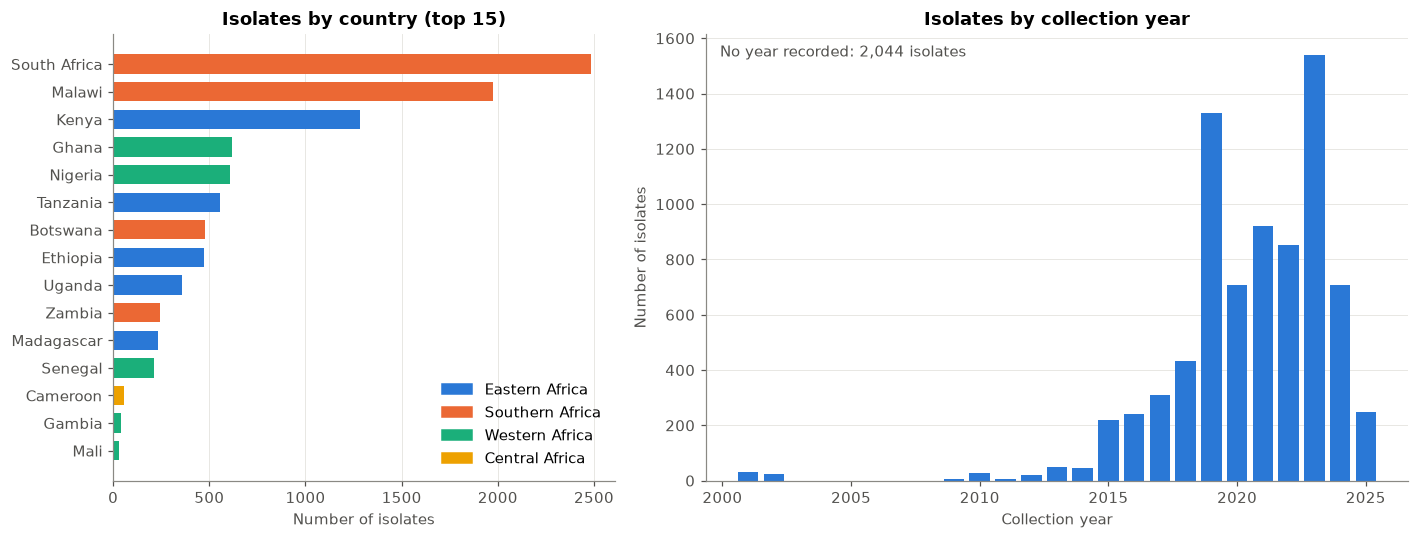

Countries: 25   Countries with 100+ isolates: 12
Top 3 countries hold 58.8% of isolates
Isolates with a recorded year collected 2015 or later: 97.3%


In [18]:
# 2.1.1 Isolates by country (top 15) and region
by_country = df['country'].value_counts()
top15 = by_country.head(15).sort_values()
region_colors = {'Eastern Africa': BLUE, 'Southern Africa': ORANGE, 'Western Africa': AQUA, 'Central Africa': YELLOW}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].barh(top15.index, top15.values, color=[region_colors[region_map[c]] for c in top15.index], height=0.7)
axes[0].legend(handles=[Patch(color=c, label=r) for r, c in region_colors.items()], loc='lower right')
axes[0].set_title('Isolates by country (top 15)')
axes[0].set_xlabel('Number of isolates')
axes[0].grid(axis='y', visible=False)

    # 2.1.2 Isolates per collection year
per_year = df['year'].value_counts().sort_index()
per_year = per_year[per_year.index >= 2000]
axes[1].bar(per_year.index, per_year.values, color=BLUE, width=0.8)
axes[1].set_title('Isolates by collection year')
axes[1].set_xlabel('Collection year')
axes[1].set_ylabel('Number of isolates')
axes[1].grid(axis='x', visible=False)
axes[1].text(0.02, 0.95, f"No year recorded: {df['year'].isna().sum():,} isolates", transform=axes[1].transAxes, color='#52514e')
fig.tight_layout()
save(fig, 'Q1_isolates_by_country_and_year')
plt.show()

print(f"Countries: {df['country'].nunique()}   Countries with 100+ isolates: {(by_country >= 100).sum()}")
print(f"Top 3 countries hold {by_country.head(3).sum() / len(df) * 100:.1f}% of isolates")
print(f"Isolates with a recorded year collected 2015 or later: {(df['year'].dropna() >= 2015).mean() * 100:.1f}%")

In [19]:
# 2.1.3 Figures behind the observations
country_table = pd.DataFrame({'rank': range(1, len(by_country) + 1), 'isolates': by_country, 'percent': by_country / len(df) * 100})
display(country_table.round(1))

region_table = df['region'].value_counts().to_frame('isolates')
region_table['percent'] = region_table['isolates'] / len(df) * 100
display(region_table.round(1))

year_table = per_year.loc[2013:]
year_table.index = year_table.index.astype(int)
display(year_table.to_frame('isolates').T)
print(f"No collection year: {df['year'].isna().sum():,} isolates ({df['year'].isna().mean() * 100:.1f}%)")

,rank,isolates,percent
country,,,
South Africa,1,2483,25.4
Malawi,2,1975,20.2
Kenya,3,1282,13.1
Ghana,4,618,6.3
Nigeria,5,609,6.2
Tanzania,6,555,5.7
Botswana,7,475,4.9
Ethiopia,8,474,4.9
Uganda,9,359,3.7


,isolates,percent
region,,
Southern Africa,5210,53.4
Eastern Africa,2941,30.1
Western Africa,1546,15.8
Central Africa,64,0.7


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
isolates,51,47,218,240,308,434,1330,709,920,853,1538,708,249


No collection year: 2,044 isolates (20.9%)


**Observations:**

- `Coverage:` 9,761 *K. pneumoniae* genomes from 25 sub-Saharan countries. Only 12 countries have 100 or more isolates, and the top three (South Africa 2,483, Malawi 1,975, Kenya 1,282) hold 58.8% of the data. Uganda has 359 isolates (9th).
- `Regions:` Southern Africa contributes 53.4% of isolates, Eastern Africa 30.1%, Western Africa 15.8% and Central Africa only 0.7% (Cameroon and the Central African Republic).
- `Time:` 97.3% of isolates with a recorded year were collected in 2015 or later, with peaks in 2019 (1,330) and 2023 (1,538). 2,044 isolates (20.9%) have no collection year, mostly from Malawi and Madagascar (section 1.7).
- `Interpretation:` the data come from research projects rather than routine surveillance, so the number of isolates per country reflects where genomic studies were funded, not where *Klebsiella* is most common.

## **Question 2:** How common are the key resistance mechanisms, overall and by country?

,Indicator,Isolates,Total,Percent,CI low,CI high
0,ESBL/AmpC genes,8046,9761,82.4,81.7,83.2
1,Carbapenemase genes,1666,9761,17.1,16.3,17.8
2,Colistin resistance,71,9761,0.7,0.6,0.9
3,MDR genotype (3+ classes),8370,9761,85.7,85.0,86.4


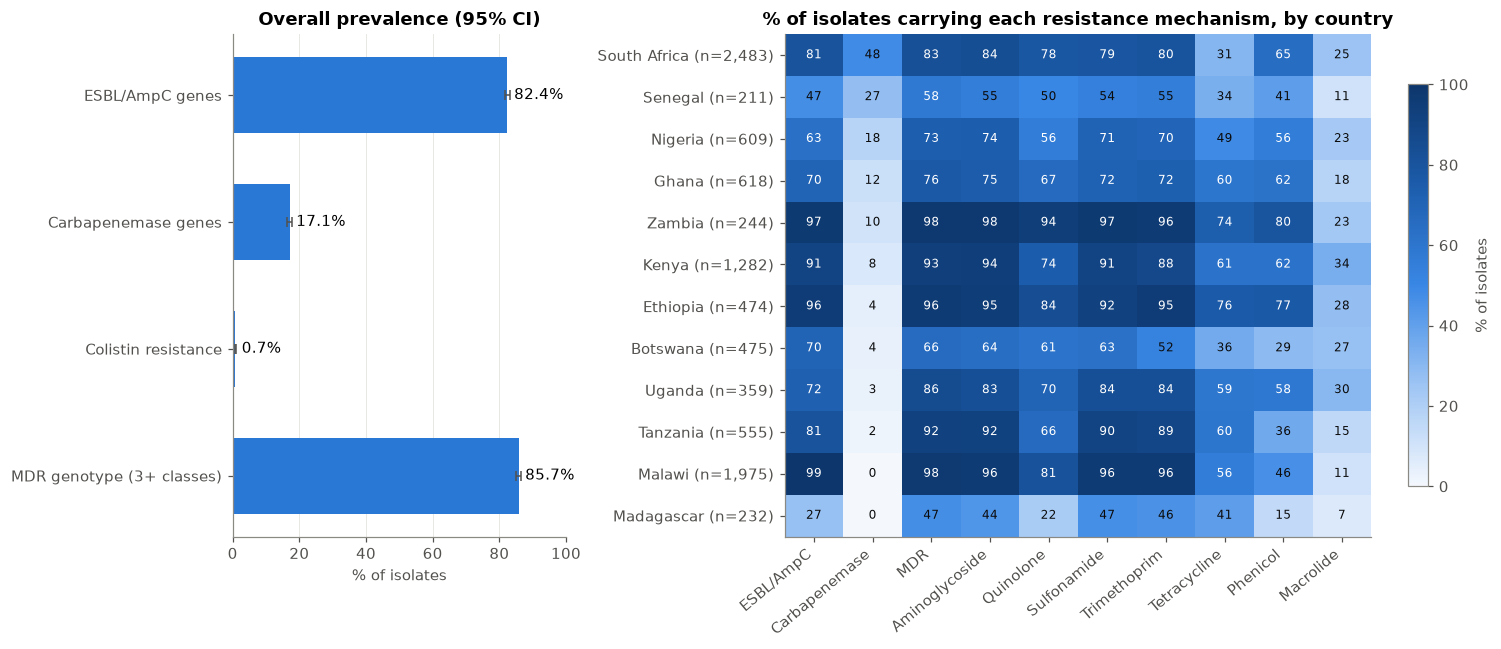

In [20]:
# 2.2.1 Overall prevalence with 95% Wilson confidence intervals
indicators = {'ESBL/AmpC genes': 'esbl', 'Carbapenemase genes': 'carbapenemase', 'Colistin resistance': 'colistin', 'MDR genotype (3+ classes)': 'mdr'}
overall = pd.DataFrame([(label, df[col].sum(), len(df)) for label, col in indicators.items()], columns=['Indicator', 'Isolates', 'Total'])
overall['Percent'] = overall['Isolates'] / overall['Total'] * 100
overall[['CI low', 'CI high']] = [np.array(wilson(k, n)) * 100 for k, n in zip(overall['Isolates'], overall['Total'])]
display(overall.round(1))
overall.round(2).to_csv(TABLES / 'Q2_overall_prevalence.csv', index=False)

    # 2.2.2 Prevalence by country (countries with 100+ isolates)
big = by_country[by_country >= 100].index
heat_cols = ['esbl', 'carbapenemase', 'mdr'] + ['Aminoglycoside', 'Quinolone', 'Sulfonamide', 'Trimethoprim', 'Tetracycline', 'Phenicol', 'Macrolide']
heat = df[df['country'].isin(big)].groupby('country')[heat_cols].mean().mul(100)
heat = heat.sort_values('carbapenemase', ascending=False)
heat.columns = ['ESBL/AmpC', 'Carbapenemase', 'MDR', 'Aminoglycoside', 'Quinolone', 'Sulfonamide', 'Trimethoprim', 'Tetracycline', 'Phenicol', 'Macrolide']
heat.round(1).to_csv(TABLES / 'Q2_prevalence_by_country.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2.2]})
y = np.arange(len(overall))[::-1]
axes[0].barh(y, overall['Percent'], color=BLUE, height=0.6)
axes[0].errorbar(overall['Percent'], y, xerr=[overall['Percent'] - overall['CI low'], overall['CI high'] - overall['Percent']], fmt='none', ecolor='#52514e', capsize=3, lw=1)
for yi, p in zip(y, overall['Percent']):
    axes[0].text(p + 2, yi, f"{p:.1f}%", va='center')
axes[0].set_yticks(y, overall['Indicator'])
axes[0].set_xlim(0, 100)
axes[0].set_xlabel('% of isolates')
axes[0].set_title('Overall prevalence (95% CI)')
axes[0].grid(axis='y', visible=False)

im = axes[1].imshow(heat.values, cmap=BLUES, vmin=0, vmax=100, aspect='auto')
axes[1].set_xticks(range(heat.shape[1]), heat.columns, rotation=40, ha='right')
axes[1].set_yticks(range(heat.shape[0]), [f"{c} (n={by_country[c]:,})" for c in heat.index])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        axes[1].text(j, i, f"{v:.0f}", ha='center', va='center', fontsize=8, color='white' if v > 55 else '#0b0b0b')
axes[1].grid(False)
axes[1].set_title('% of isolates carrying each resistance mechanism, by country')
fig.colorbar(im, ax=axes[1], label='% of isolates', shrink=0.8)
fig.tight_layout()
save(fig, 'Q2_resistance_prevalence')
plt.show()

In [21]:
# 2.2.3 Figures behind the observations
display(heat.assign(isolates=by_country.reindex(heat.index)).round(1))
for n in [30, 100]:
    low, high = wilson(n / 2, n)
    print(f"95% CI around 50% with {n} isolates: {low * 100:.0f}-{high * 100:.0f}%")

,ESBL/AmpC,Carbapenemase,MDR,Aminoglycoside,Quinolone,Sulfonamide,Trimethoprim,Tetracycline,Phenicol,Macrolide,isolates
country,,,,,,,,,,,
South Africa,80.7,48.1,82.7,83.6,77.9,79.2,80.2,31.0,64.8,25.4,2483
Senegal,46.9,27.5,57.8,55.0,49.8,53.6,55.0,33.6,40.8,10.9,211
Nigeria,63.2,17.9,73.2,73.9,55.8,71.3,69.8,48.8,55.8,22.7,609
Ghana,70.4,12.1,76.2,74.8,66.5,71.8,72.5,59.7,62.0,17.8,618
Zambia,97.1,10.2,98.0,98.0,94.3,97.1,95.9,73.8,79.9,23.4,244
Kenya,91.0,8.1,93.4,93.9,74.3,91.0,87.8,61.5,61.6,34.0,1282
Ethiopia,95.6,4.4,96.2,95.1,84.2,92.4,95.4,76.2,76.6,27.6,474
Botswana,70.3,3.8,65.9,64.4,60.8,62.5,52.0,35.6,29.3,26.9,475
Uganda,72.1,3.3,85.8,83.3,70.2,83.6,83.6,59.1,58.5,30.4,359


95% CI around 50% with 30 isolates: 33-67%
95% CI around 50% with 100 isolates: 40-60%


**Observations:**

- `Overall:` 82.4% (95% CI 81.7–83.2%) of isolates carry ESBL/AmpC genes, 17.1% (16.3–17.8%) carry a carbapenemase gene, 0.7% carry colistin resistance determinants and 85.7% have an MDR genotype.
- `Carbapenemases vary widely by country:` from 48% in South Africa, 27% in Senegal, 18% in Nigeria and 12% in Ghana, down to 0–2% in Malawi, Madagascar and Tanzania.
- `ESBL/AmpC is near-universal in several countries:` Malawi 99%, Zambia 97%, Ethiopia 96%, Kenya 91%. The lowest rates are in Madagascar (27%) and Senegal (47%).
- `Why only countries with 100+ isolates:` with 30 isolates, a 50% estimate has a 95% CI of 33–67%. With 100 isolates it narrows to 40–60%, precise enough to compare countries (2.2.3).
- `Pattern:` aminoglycoside, sulfonamide and trimethoprim resistance rise and fall with ESBL/AmpC in every country, which hints that these genes travel together (explored in Question 6). Macrolide genes are the least common (7–34%).

## **Question 3:** Which specimens do the isolates come from, and how many antibiotic classes does each isolate resist?

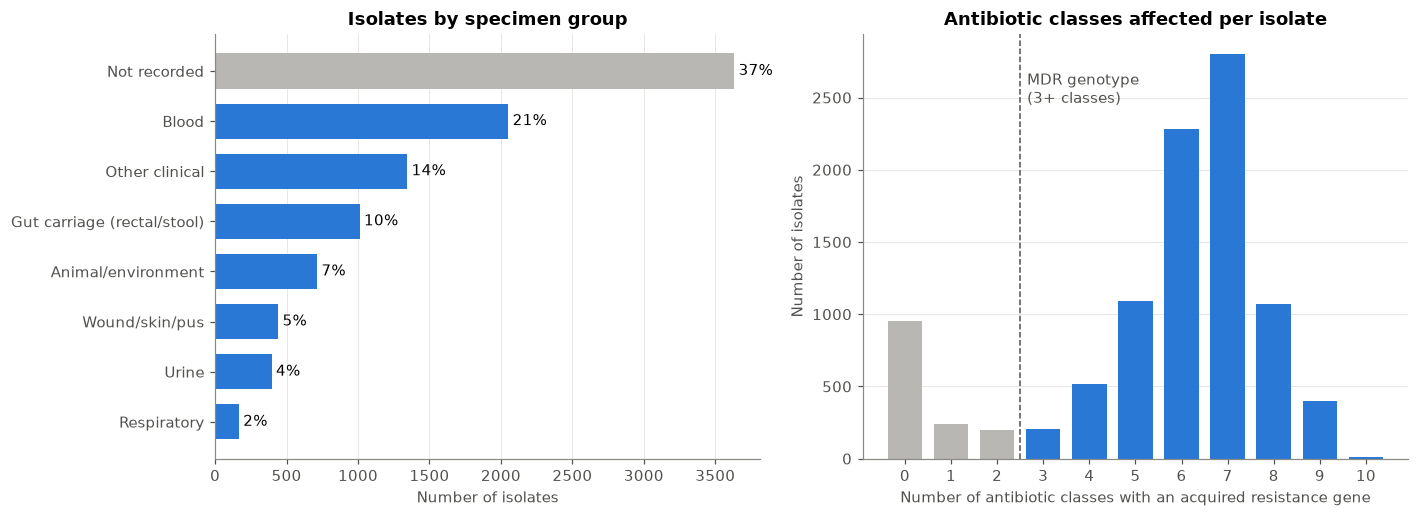

Classes affected - mean: 5.56  median: 6  IQR: 5-7  skew: -1.15
Isolates with no acquired resistance class: 9.7%
Specimen not recorded: 37.2%


In [22]:
# 2.3.1 Specimen groups
spec_counts = df['specimen'].value_counts().sort_values()

    # 2.3.2 Number of antibiotic classes affected per isolate
class_dist = df['n_classes'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(spec_counts.index, spec_counts.values, color=[GREY if s == 'Not recorded' else BLUE for s in spec_counts.index], height=0.7)
for i, v in enumerate(spec_counts.values):
    axes[0].text(v + 30, i, f"{v / len(df) * 100:.0f}%", va='center')
axes[0].set_title('Isolates by specimen group')
axes[0].set_xlabel('Number of isolates')
axes[0].grid(axis='y', visible=False)

axes[1].bar(class_dist.index, class_dist.values, color=[GREY if k < 3 else BLUE for k in class_dist.index], width=0.75)
axes[1].axvline(2.5, color='#52514e', ls='--', lw=1)
axes[1].text(2.65, class_dist.max() * 0.88, 'MDR genotype\n(3+ classes)', color='#52514e')
axes[1].set_title('Antibiotic classes affected per isolate')
axes[1].set_xlabel('Number of antibiotic classes with an acquired resistance gene')
axes[1].set_ylabel('Number of isolates')
axes[1].set_xticks(class_dist.index)
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
save(fig, 'Q3_specimens_and_classes')
plt.show()

stats = df['n_classes'].describe()
print(f"Classes affected - mean: {stats['mean']:.2f}  median: {df['n_classes'].median():.0f}  IQR: {df['n_classes'].quantile(0.25):.0f}-{df['n_classes'].quantile(0.75):.0f}  skew: {df['n_classes'].skew():.2f}")
print(f"Isolates with no acquired resistance class: {(df['n_classes'] == 0).mean() * 100:.1f}%")
print(f"Specimen not recorded: {(df['specimen'] == 'Not recorded').mean() * 100:.1f}%")

In [23]:
# 2.3.3 Figures behind the observations
spec_table = df['specimen'].value_counts().to_frame('isolates')
spec_table['% of all'] = spec_table['isolates'] / len(df) * 100
spec_table['% of recorded'] = spec_table['isolates'] / (df['specimen'] != 'Not recorded').sum() * 100
spec_table.loc['Not recorded', '% of recorded'] = np.nan
display(spec_table.round(1))

class_table = class_dist.to_frame('isolates')
class_table['percent'] = class_table['isolates'] / len(df) * 100
display(class_table.round(1))

,isolates,% of all,% of recorded
specimen,,,
Not recorded,3633,37.2,NaN
Blood,2052,21.0,33.5
Other clinical,1345,13.8,21.9
Gut carriage (rectal/stool),1012,10.4,16.5
Animal/environment,714,7.3,11.7
Wound/skin/pus,442,4.5,7.2
Urine,396,4.1,6.5
Respiratory,167,1.7,2.7


,isolates,percent
n_classes,,
0,950,9.7
1,242,2.5
2,199,2.0
3,204,2.1
4,514,5.3
5,1088,11.1
6,2284,23.4
7,2799,28.7
8,1070,11.0


**Observations:**

- `Specimens:` the specimen is not recorded for 37.2% of isolates. Blood is the most common recorded source (21% of all isolates, 33.5% of those with a specimen recorded), followed by other clinical samples (14%), gut carriage (10%) and animal/environmental samples (7%). Most isolates with no specimen come from Malawi, Madagascar, Zambia, Senegal and Tanzania (section 1.7), so the specimen breakdown mostly reflects the other countries.
- `Classes affected:` the median isolate carries resistance genes for 6 antibiotic classes (IQR 5–7; mean 5.56). The distribution is left-skewed (skewness −1.15).
- `Two populations:` the distribution has two peaks. 9.7% of isolates carry no acquired resistance at all, while most cluster at 6–7 classes, with very few in between. This suggests most isolates either have no resistance plasmids or carry large multi-resistance plasmids.
- `Caution:` laboratories tend to sequence isolates that are already known to be resistant, so the true MDR rate in all *Klebsiella* infections is likely lower than 85.7%.

# **3.0 DIAGNOSTIC ANALYSIS**

## **Question 4:** Why is carbapenemase carriage so much higher in South Africa than in the rest of sub-Saharan Africa?

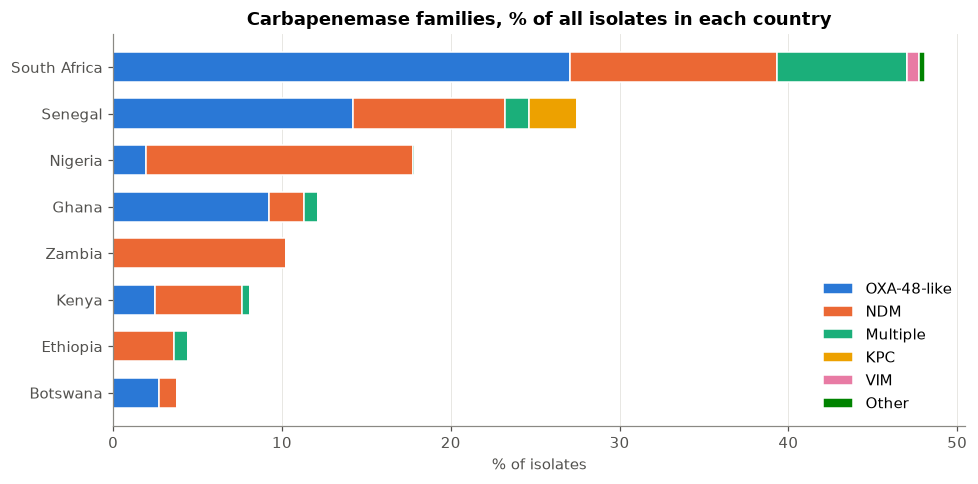

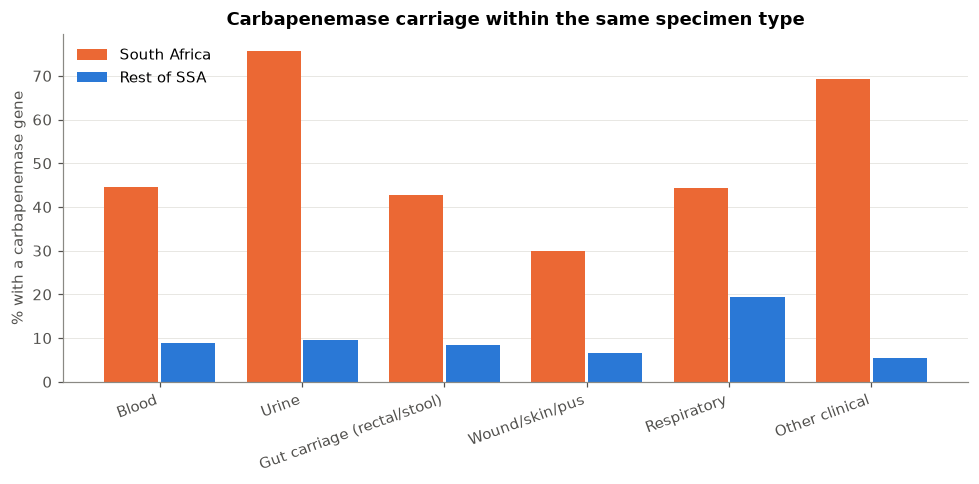

All isolates:  South Africa 48.1% vs rest 6.5%  (chi2 = 2261, p < 0.001)
Blood only:    South Africa 44.7% vs rest 9.0%  (chi2 = 334, p < 0.001)


In [24]:
# 3.4.1 Which carbapenemase families drive it?
carb_countries = heat.index[:8]
carb_mix = pd.crosstab(df['country'], df['carb_type'], normalize=False).reindex(carb_countries).fillna(0)
carb_mix = carb_mix.div(by_country.reindex(carb_countries), axis=0) * 100
carb_mix = carb_mix[[c for c in ['OXA-48-like', 'NDM', 'Multiple', 'KPC', 'VIM', 'Other'] if c in carb_mix.columns]]

    # 3.4.2 Is it explained by the type of specimen sampled?
df['sa'] = np.where(df['country'] == 'South Africa', 'South Africa', 'Rest of SSA')
human_specimens = ['Blood', 'Urine', 'Gut carriage (rectal/stool)', 'Wound/skin/pus', 'Respiratory', 'Other clinical']
by_spec = df[df['specimen'].isin(human_specimens)].pivot_table(index='specimen', columns='sa', values='carbapenemase', aggfunc='mean').mul(100).reindex(human_specimens)

fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(carb_mix))
type_colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]
for col, color in zip(carb_mix.columns, type_colors):
    ax.barh(carb_mix.index[::-1], carb_mix[col][::-1], left=left[::-1], color=color, label=col, height=0.65, edgecolor='white', linewidth=1)
    left = left + carb_mix[col].values
ax.set_title('Carbapenemase families, % of all isolates in each country')
ax.set_xlabel('% of isolates')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save(fig, 'Q4a_carbapenemase_families')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(by_spec))
ax.bar(x - 0.2, by_spec['South Africa'], width=0.38, color=ORANGE, label='South Africa')
ax.bar(x + 0.2, by_spec['Rest of SSA'], width=0.38, color=BLUE, label='Rest of SSA')
ax.set_xticks(x, by_spec.index, rotation=20, ha='right')
ax.set_ylabel('% with a carbapenemase gene')
ax.set_title('Carbapenemase carriage within the same specimen type')
ax.legend()
ax.grid(axis='x', visible=False)
fig.tight_layout()
save(fig, 'Q4b_carbapenemase_by_specimen')
plt.show()

table = pd.crosstab(df['sa'], df['carbapenemase'])
chi2, p, _, _ = chi2_contingency(table)
blood = df[df['specimen'] == 'Blood']
chi2_b, p_b, _, _ = chi2_contingency(pd.crosstab(blood['sa'], blood['carbapenemase']))
print(f"All isolates:  South Africa {df.loc[df['sa'] == 'South Africa', 'carbapenemase'].mean() * 100:.1f}% vs rest {df.loc[df['sa'] == 'Rest of SSA', 'carbapenemase'].mean() * 100:.1f}%  (chi2 = {chi2:.0f}, {fmt_p(p)})")
print(f"Blood only:    South Africa {blood.loc[blood['sa'] == 'South Africa', 'carbapenemase'].mean() * 100:.1f}% vs rest {blood.loc[blood['sa'] == 'Rest of SSA', 'carbapenemase'].mean() * 100:.1f}%  (chi2 = {chi2_b:.0f}, {fmt_p(p_b)})")

In [25]:
# 3.4.3 Is it driven by a few studies that targeted resistant isolates?
sa = df[df['country'] == 'South Africa']
studies = sa.groupby('bioproject_acc').agg(isolates=('carbapenemase', 'size'), pct_carbapenemase=('carbapenemase', 'mean'), main_specimen=('specimen', lambda s: s.value_counts().index[0]))
studies['pct_carbapenemase'] = studies['pct_carbapenemase'] * 100
studies = studies.sort_values('isolates', ascending=False)
display(studies.head(8).round(1))
studies.round(1).to_csv(TABLES / 'Q4_south_africa_studies.csv')

targeted = studies[(studies['pct_carbapenemase'] >= 80) & (studies['isolates'] >= 30)].index
rest = sa[~sa['bioproject_acc'].isin(targeted)]
print(f"Studies with 80%+ carbapenemase (likely selected for resistance): {len(targeted)}, holding {sa['bioproject_acc'].isin(targeted).sum():,} isolates")
print(f"South Africa carbapenemase without those studies: {rest['carbapenemase'].mean() * 100:.1f}%  (n = {len(rest):,})")

,isolates,pct_carbapenemase,main_specimen
bioproject_acc,,,
PRJNA1369306,691,51.8,Blood
PRJEB63361,405,98.5,Other clinical
PRJNA1200291,215,31.6,Not recorded
PRJNA796486,197,39.6,Blood
PRJNA1175467,185,21.6,Blood
PRJNA1253337,152,3.9,Other clinical
PRJNA1035075,85,88.2,Not recorded
PRJNA1077801,79,21.5,Blood


Studies with 80%+ carbapenemase (likely selected for resistance): 2, holding 490 isolates
South Africa carbapenemase without those studies: 36.1%  (n = 1,993)


In [26]:
# 3.4.4 Figures behind the observations
display(studies[studies['isolates'] >= 30].sort_values('pct_carbapenemase', ascending=False).head(5).round(1))
display(carb_mix.round(1))
display(by_spec.round(1))
display(genes[genes['carbapenemase'] & genes['target_acc'].isin(sa['target_acc'])]['gene'].value_counts().head(6).to_frame('South African isolates'))
rest_ssa = df.loc[df['sa'] == 'Rest of SSA', 'carbapenemase'].mean() * 100
print(f"South Africa without targeted studies vs rest of SSA: {rest['carbapenemase'].mean() * 100:.1f}% / {rest_ssa:.1f}% = {rest['carbapenemase'].mean() * 100 / rest_ssa:.1f} times")

,isolates,pct_carbapenemase,main_specimen
bioproject_acc,,,
PRJEB63361,405,98.5,Other clinical
PRJNA1035075,85,88.2,Not recorded
PRJNA1369306,691,51.8,Blood
PRJNA796486,197,39.6,Blood
PRJNA1200291,215,31.6,Not recorded


carb_type,OXA-48-like,NDM,Multiple,KPC,VIM,Other
country,,,,,,
South Africa,27.1,12.2,7.7,0.0,0.7,0.3
Senegal,14.2,9.0,1.4,2.8,0.0,0.0
Nigeria,2.0,15.8,0.2,0.0,0.0,0.0
Ghana,9.2,2.1,0.8,0.0,0.0,0.0
Zambia,0.0,10.2,0.0,0.0,0.0,0.0
Kenya,2.5,5.1,0.5,0.0,0.0,0.0
Ethiopia,0.0,3.6,0.8,0.0,0.0,0.0
Botswana,2.7,1.1,0.0,0.0,0.0,0.0


sa,Rest of SSA,South Africa
specimen,,
Blood,9.0,44.7
Urine,9.6,75.8
Gut carriage (rectal/stool),8.3,42.8
Wound/skin/pus,6.5,29.8
Respiratory,19.5,44.4
Other clinical,5.6,69.4


,South African isolates
gene,
blaOXA-181,668
blaNDM-1,452
blaOXA-232,132
blaOXA-48,69
blaNDM-5,34
blaVIM-1,21


South Africa without targeted studies vs rest of SSA: 36.1% / 6.5% = 5.6 times


**Observations:**

- `The gap is large and significant:` 48.1% of South African isolates carry a carbapenemase gene against 6.5% in the rest of sub-Saharan Africa (χ² = 2,261, p < 0.001).
- `It is driven by OXA-48-like enzymes:` OXA-48-like enzymes (mainly OXA-181 and OXA-232) are found in 27.1% of all South African isolates, plus NDM in 12.2%. Other countries have different profiles: Nigeria is dominated by NDM, while Ghana and Senegal resemble South Africa's OXA-48-like pattern.
- `It is not explained by specimen type:` the gap persists within every specimen group. In blood isolates alone the figure is 44.7% vs 9.0% (χ² = 334, p < 0.001), and in urine 75.8% vs 9.6%.
- `Part of it is sampling:` two South African studies (490 isolates) are ≥80% carbapenemase-positive, so they most likely collected carbapenem-resistant isolates on purpose. Without them South Africa drops from 48.1% to 36.1%, which is still 5.6 times the rest of the region (6.5%).
- `Why 80% and 30 isolates:` the two flagged studies (98.5% and 88.2%) stand well apart from the next highest (51.8%). The 30-isolate minimum stops very small studies from being flagged by chance.
- `Diagnosis:` South Africa's high rate is partly a sampling effect, but a real and much higher burden remains, driven by OXA-48-like carbapenemases circulating in its hospitals.

## **Question 5:** Is the rise and fall in carbapenemase carriage over time real, or an effect of which countries were sampled each year?

Years left out (fewer than 50 isolates): {2001.0: 30, 2002.0: 23, 2009.0: 7, 2010.0: 27, 2011.0: 6, 2012.0: 19, 2014.0: 47}


,isolates,all_ssa,sa_share,without_sa
year,,,,
2013,51,21.6,41.2,6.7
2015,218,12.8,0.5,12.4
2016,240,15.4,6.2,12.4
2017,308,13.3,24.4,15.0
2018,434,19.6,37.1,8.4
2019,1330,33.9,46.5,8.0
2020,709,23.1,35.8,6.8
2021,920,14.2,14.3,7.4
2022,853,20.3,22.4,12.5


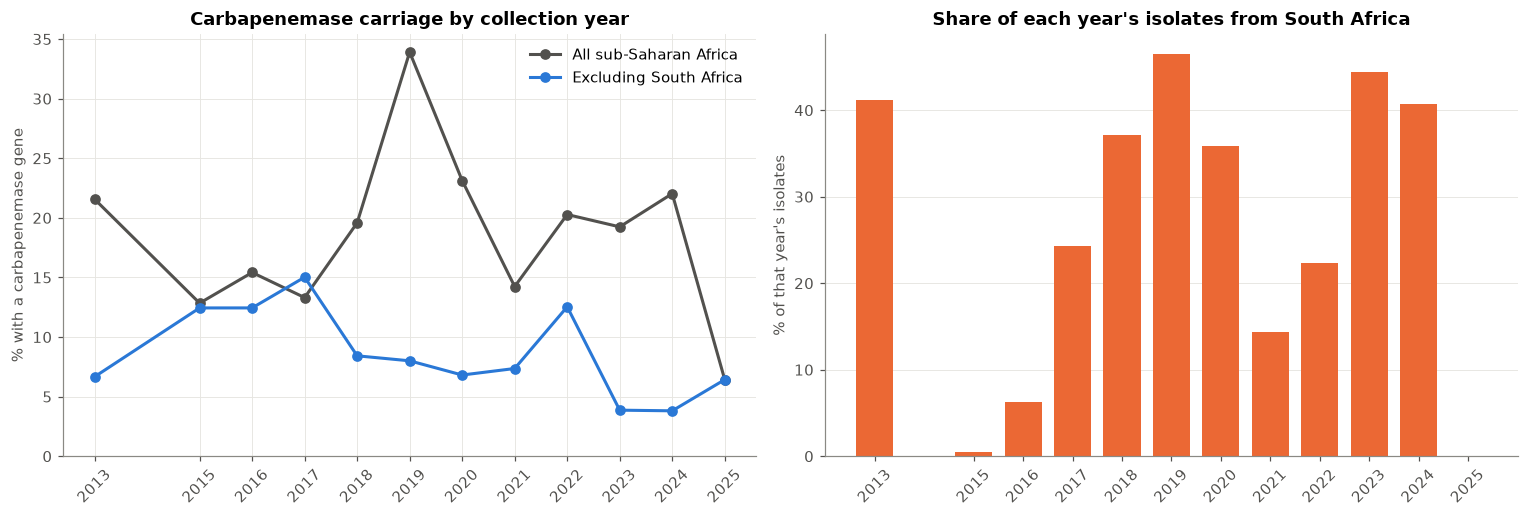

Correlation between South Africa's share and the overall yearly rate: r = 0.81


In [27]:
# 3.5.1 Yearly prevalence with and without South Africa (years with 50+ isolates)
recent = df[df['year'].notna()]
yearly = recent.groupby('year').agg(isolates=('carbapenemase', 'size'), all_ssa=('carbapenemase', 'mean'), sa_share=('sa', lambda s: (s == 'South Africa').mean()))
yearly['without_sa'] = recent[recent['sa'] == 'Rest of SSA'].groupby('year')['carbapenemase'].mean()
yearly[['all_ssa', 'without_sa', 'sa_share']] = yearly[['all_ssa', 'without_sa', 'sa_share']] * 100
print("Years left out (fewer than 50 isolates):", yearly.loc[yearly['isolates'] < 50, 'isolates'].to_dict())
yearly = yearly[yearly['isolates'] >= 50]
yearly.index = yearly.index.astype(int)
display(yearly.round(1))
yearly.round(1).to_csv(TABLES / 'Q5_yearly_carbapenemase.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(yearly.index, yearly['all_ssa'], marker='o', color='#52514e', lw=2, label='All sub-Saharan Africa')
axes[0].plot(yearly.index, yearly['without_sa'], marker='o', color=BLUE, lw=2, label='Excluding South Africa')
axes[0].set_ylabel('% with a carbapenemase gene')
axes[0].set_title('Carbapenemase carriage by collection year')
axes[0].legend()
axes[0].set_ylim(0, None)

axes[1].bar(yearly.index, yearly['sa_share'], color=ORANGE, width=0.75)
axes[1].set_ylabel('% of that year\'s isolates')
axes[1].set_title('Share of each year\'s isolates from South Africa')
axes[1].grid(axis='x', visible=False)
for ax in axes:
    ax.set_xticks(yearly.index)
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
save(fig, 'Q5_trend_vs_sampling')
plt.show()

r = np.corrcoef(yearly['sa_share'], yearly['all_ssa'])[0, 1]
print(f"Correlation between South Africa's share and the overall yearly rate: r = {r:.2f}")

In [28]:
# 3.5.2 Figures behind the observations
print(f"All sub-Saharan Africa: {yearly['all_ssa'].min():.1f}% to {yearly['all_ssa'].max():.1f}%, peak in {yearly['all_ssa'].idxmax()}")
print(f"Excluding South Africa: {yearly['without_sa'].min():.1f}% to {yearly['without_sa'].max():.1f}%")
print(f"South Africa's share in the peak year: {yearly.loc[yearly['all_ssa'].idxmax(), 'sa_share']:.1f}%")

All sub-Saharan Africa: 6.4% to 33.9%, peak in 2019
Excluding South Africa: 3.8% to 15.0%
South Africa's share in the peak year: 46.5%


**Observations:**

- `The pooled trend is misleading:` carbapenemase carriage across sub-Saharan Africa appears to swing between 6.4% and 33.9%, peaking in 2019.
- `The swings follow South Africa's share of the data:` in 2019, South Africa supplied 46.5% of isolates. Across years, South Africa's share and the overall rate are strongly correlated (r = 0.81). In 2025, with no South African isolates yet, the rate falls to 6.4%.
- `Without South Africa there is no rising trend:` the rate stays between 3.8% and 15%, and it is lowest in 2023–2024 (about 4%).
- `Missing years:` the 20.9% of isolates with no year come mostly from low-carbapenemase countries such as Malawi and Madagascar (2.9% carbapenemase vs 20.8% for isolates with a year). Leaving them out raises South Africa's share of the yearly data from 25.4% to 31.9%, which strengthens the conclusion below.
- `Why 50+ isolates per year:` years with fewer isolates (2001–2012 and 2014, 6–47 isolates each) are left out, because a handful of isolates from one study can swing the yearly rate.
- `Diagnosis:` the apparent rise and fall is a composition effect, a Simpson's-paradox-type artefact. A trend should only be read within countries, or after accounting for which countries were sampled each year.

## **Question 6:** Why are most isolates multidrug-resistant? Which resistance genes travel together?

,mean,median,size
esbl,,,
ESBL/AmpC absent,1.56,0.0,1715
ESBL/AmpC present,5.41,6.0,8046


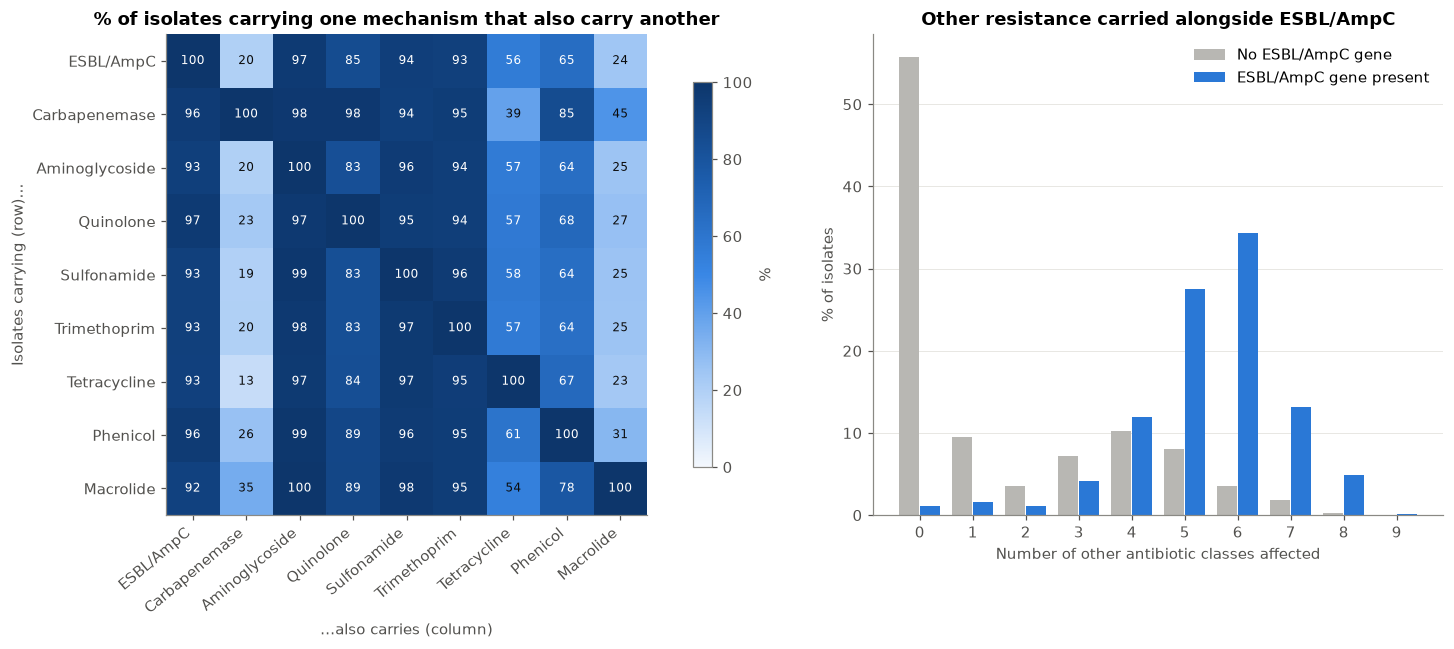

In [29]:
# 3.6.1 Probability of carrying class B given class A
co_cols = ['esbl', 'carbapenemase'] + ['Aminoglycoside', 'Quinolone', 'Sulfonamide', 'Trimethoprim', 'Tetracycline', 'Phenicol', 'Macrolide']
co_labels = ['ESBL/AmpC', 'Carbapenemase', 'Aminoglycoside', 'Quinolone', 'Sulfonamide', 'Trimethoprim', 'Tetracycline', 'Phenicol', 'Macrolide']
flags = df[co_cols].astype(int)
co = pd.DataFrame({b: [flags.loc[flags[a] == 1, b].mean() * 100 for a in co_cols] for b in co_cols}, index=co_cols)
co.index, co.columns = co_labels, co_labels

    # 3.6.2 Other classes carried with and without an ESBL/AmpC gene
df['other_classes'] = df['n_classes'] - df['Beta-Lactam'].astype(int)
esbl_compare = df.groupby('esbl')['other_classes'].agg(['mean', 'median', 'size']).rename(index={True: 'ESBL/AmpC present', False: 'ESBL/AmpC absent'})
display(esbl_compare.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.6, 1]})
im = axes[0].imshow(co.values, cmap=BLUES, vmin=0, vmax=100)
axes[0].set_xticks(range(len(co_labels)), co_labels, rotation=40, ha='right')
axes[0].set_yticks(range(len(co_labels)), co_labels)
for i in range(len(co_labels)):
    for j in range(len(co_labels)):
        v = co.iloc[i, j]
        axes[0].text(j, i, f"{v:.0f}", ha='center', va='center', fontsize=8, color='white' if v > 55 else '#0b0b0b')
axes[0].set_xlabel('...also carries (column)')
axes[0].set_ylabel('Isolates carrying (row)...')
axes[0].set_title('% of isolates carrying one mechanism that also carry another')
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8, label='%')

dist = pd.crosstab(df['other_classes'], df['esbl'], normalize='columns') * 100
axes[1].bar(dist.index - 0.2, dist[False], width=0.38, color=GREY, label='No ESBL/AmpC gene')
axes[1].bar(dist.index + 0.2, dist[True], width=0.38, color=BLUE, label='ESBL/AmpC gene present')
axes[1].set_xlabel('Number of other antibiotic classes affected')
axes[1].set_ylabel('% of isolates')
axes[1].set_title('Other resistance carried alongside ESBL/AmpC')
axes[1].set_xticks(dist.index)
axes[1].legend()
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
save(fig, 'Q6_gene_cooccurrence')
plt.show()

top_esbl = genes[genes['esbl']]['gene'].value_counts().head(5)

In [30]:
# 3.6.3 Figures behind the observations
display(co.round(1))
print("Most common ESBL/AmpC genes (% of all isolates):", (top_esbl / len(df) * 100).round(1).to_dict())

,ESBL/AmpC,Carbapenemase,Aminoglycoside,Quinolone,Sulfonamide,Trimethoprim,Tetracycline,Phenicol,Macrolide
ESBL/AmpC,100.0,19.8,96.7,85.4,94.0,93.2,56.1,64.6,24.3
Carbapenemase,95.7,100.0,98.0,97.8,93.6,95.0,39.4,85.5,44.6
Aminoglycoside,93.4,19.6,100.0,83.0,96.0,94.4,56.9,64.1,25.4
Quinolone,96.7,23.0,97.3,100.0,95.2,94.4,57.4,67.6,26.6
Sulfonamide,93.3,19.2,98.5,83.3,100.0,96.2,58.3,64.1,25.5
Trimethoprim,93.1,19.6,97.6,83.3,96.9,100.0,57.4,63.6,25.1
Tetracycline,92.6,13.5,97.2,83.7,97.0,94.8,100.0,67.2,23.4
Phenicol,96.3,26.4,98.9,88.9,96.3,94.9,60.7,100.0,30.6
Macrolide,92.1,35.0,99.7,89.2,97.5,95.2,53.7,77.8,100.0


Most common ESBL/AmpC genes (% of all isolates): {'blaCTX-M-15': 76.3, 'blaOXA-1': 30.5, 'blaOXA': 3.4, 'blaSHV-187': 3.2, 'blaCTX-M': 1.8}


**Observations:**

- `Resistance genes travel together:` among isolates with an ESBL/AmpC gene, 97% also carry aminoglycoside resistance, 94% sulfonamide, 93% trimethoprim and 85% quinolone. Among carbapenemase carriers, 96% also carry ESBL/AmpC genes and 98% carry aminoglycoside and quinolone resistance.
- `ESBL marks heavy MDR:` isolates with an ESBL/AmpC gene carry a median of 6 other resistant classes, against 0 for isolates without one (means 5.41 vs 1.56).
- `One gene dominates:` *blaCTX-M-15* is present in 76.3% of all isolates, often alongside *blaOXA-1* (30.5%) and *aac(6')-Ib-cr*. This combination is typical of multi-resistance plasmids carried by successful *K. pneumoniae* lineages.
- `Diagnosis:` the MDR rate is high because resistance genes are linked on shared plasmids, not acquired one by one. Using any one of these antibiotics can therefore select for resistance to the others (co-selection).

## **Question 7:** How does Uganda compare with its Eastern African neighbours, and what explains the differences?

indicator,Carbapenemase,ESBL/AmpC,MDR genotype
country,,,
Ethiopia,4.4,95.6,96.2
Kenya,8.1,91.0,93.4
Madagascar,0.0,26.7,47.0
Tanzania,1.6,80.5,92.1
Uganda,3.3,72.1,85.8


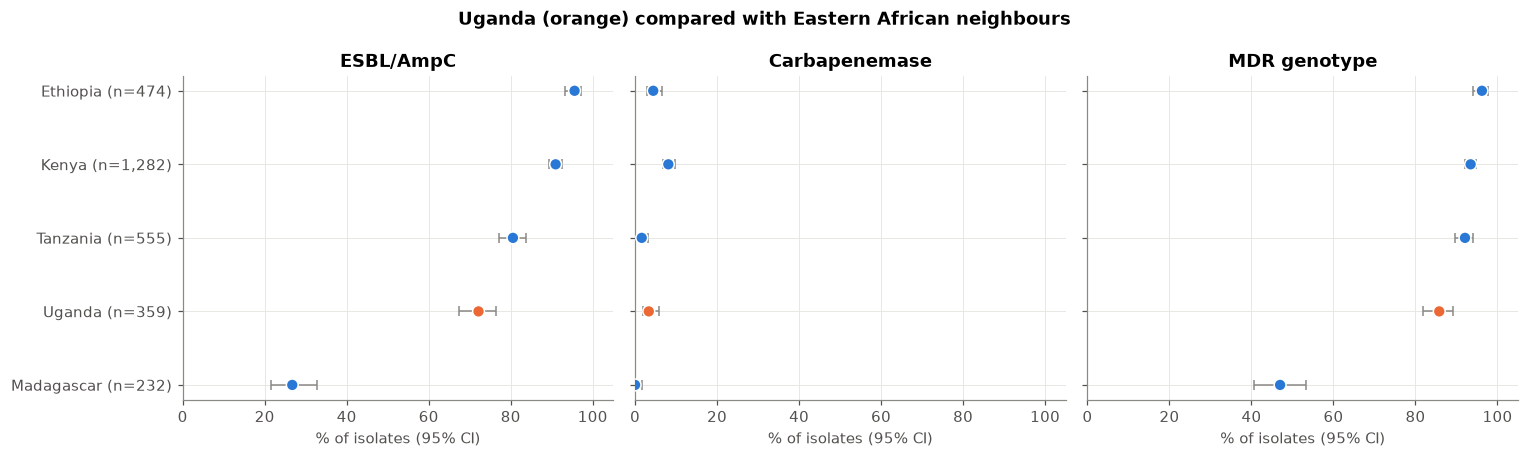

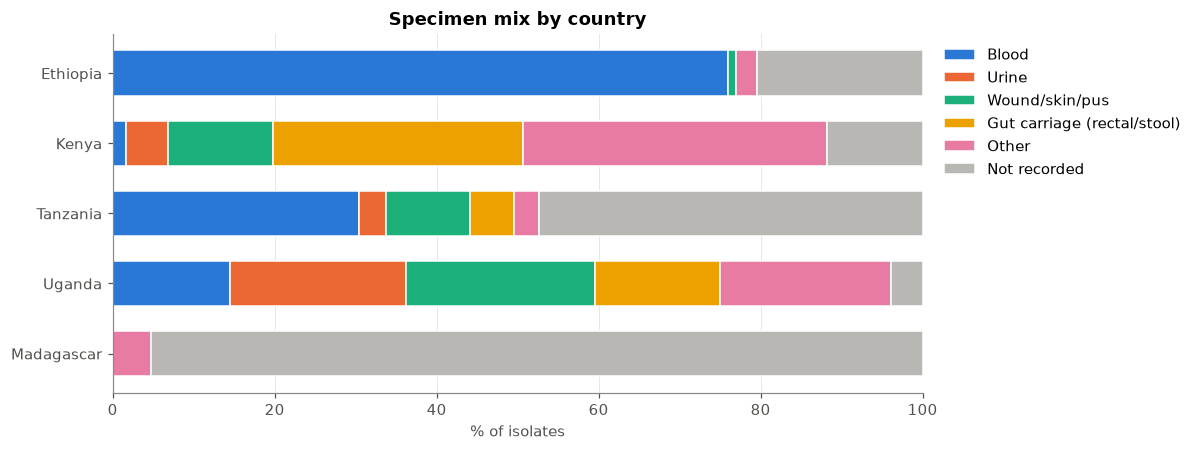

In [31]:
# 3.7.1 Prevalence with 95% CI for Eastern African countries with 100+ isolates
east = [c for c in by_country[by_country >= 100].index if region_map.get(c) == 'Eastern Africa']
rows = []
for country in east:
    sub = df[df['country'] == country]
    for label, col in [('ESBL/AmpC', 'esbl'), ('Carbapenemase', 'carbapenemase'), ('MDR genotype', 'mdr')]:
        low, high = wilson(sub[col].sum(), len(sub))
        rows.append({'country': country, 'indicator': label, 'n': len(sub), 'pct': sub[col].mean() * 100, 'low': low * 100, 'high': high * 100})
ea = pd.DataFrame(rows)
display(ea.pivot(index='country', columns='indicator', values='pct').round(1))
ea.round(1).to_csv(TABLES / 'Q7_east_africa_comparison.csv', index=False)

    # 3.7.2 Prevalence by country, Uganda highlighted
order = ea[ea['indicator'] == 'ESBL/AmpC'].sort_values('pct')['country'].tolist()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, label in zip(axes, ['ESBL/AmpC', 'Carbapenemase', 'MDR genotype']):
    part = ea[ea['indicator'] == label].set_index('country').loc[order]
    colors = [ORANGE if c == 'Uganda' else BLUE for c in order]
    ax.errorbar(part['pct'], range(len(order)), xerr=[part['pct'] - part['low'], part['high'] - part['pct']], fmt='none', ecolor='#8a8984', lw=1, capsize=3)
    ax.scatter(part['pct'], range(len(order)), c=colors, s=60, zorder=3, edgecolors='white', linewidths=1)
    ax.set_title(label)
    ax.set_xlim(0, 105)
    ax.set_xlabel('% of isolates (95% CI)')
axes[0].set_yticks(range(len(order)), [f"{c} (n={by_country[c]:,})" for c in order])
fig.suptitle('Uganda (orange) compared with Eastern African neighbours', fontweight='bold')
fig.tight_layout()
save(fig, 'Q7a_uganda_vs_east_africa')
plt.show()

    # 3.7.3 Specimen mix by country
mix_group = df['specimen'].replace({'Respiratory': 'Other', 'Other clinical': 'Other', 'Animal/environment': 'Other'})
in_east = df['country'].isin(east)
mix = pd.crosstab(df.loc[in_east, 'country'], mix_group[in_east], normalize='index') * 100
mix = mix[['Blood', 'Urine', 'Wound/skin/pus', 'Gut carriage (rectal/stool)', 'Other', 'Not recorded']]

fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(order))
for col, color in zip(mix.columns, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY]):
    vals = mix.loc[order, col].values
    ax.barh(order, vals, left=left, color=color, label=col, height=0.65, edgecolor='white', linewidth=1)
    left += vals
ax.set_title('Specimen mix by country')
ax.set_xlabel('% of isolates')
ax.set_xlim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save(fig, 'Q7b_specimen_mix_east_africa')
plt.show()

In [32]:
# 3.7.4 Uganda: resistance by specimen and the studies behind the data
ug = df[df['country'] == 'Uganda']
display(ug.groupby('specimen').agg(isolates=('esbl', 'size'), pct_esbl=('esbl', 'mean'), pct_mdr=('mdr', 'mean'), mean_classes=('n_classes', 'mean'))
        .assign(pct_esbl=lambda t: t['pct_esbl'] * 100, pct_mdr=lambda t: t['pct_mdr'] * 100).sort_values('isolates', ascending=False).round(1))
print(f"Uganda studies (BioProjects): {ug['bioproject_acc'].nunique()}   Largest study share: {ug['bioproject_acc'].value_counts(normalize=True).iloc[0] * 100:.0f}%")
print(f"Uganda collection years: {ug['year'].min():.0f}-{ug['year'].max():.0f}")
print("Top Uganda carbapenemase genes:", genes[genes['carbapenemase'] & genes['target_acc'].isin(ug['target_acc'])]['gene'].value_counts().to_dict())

ea_df = df[df['country'].isin(east)]
chi2_u, p_u, _, _ = chi2_contingency(pd.crosstab(ea_df['country'] == 'Uganda', ea_df['esbl']))
print(f"ESBL/AmpC Uganda {ug['esbl'].mean() * 100:.1f}% vs other Eastern African countries {ea_df.loc[ea_df['country'] != 'Uganda', 'esbl'].mean() * 100:.1f}%: chi2 = {chi2_u:.1f}, {fmt_p(p_u)}")
ug_blood = ug[ug['specimen'] == 'Blood']
print(f"Uganda blood isolates only: ESBL/AmpC {ug_blood['esbl'].mean() * 100:.1f}% (n = {len(ug_blood)})")

,isolates,pct_esbl,pct_mdr,mean_classes
specimen,,,,
Wound/skin/pus,84,81.0,94.0,6.0
Urine,78,70.5,85.9,5.8
Gut carriage (rectal/stool),55,36.4,58.2,3.4
Blood,52,88.5,98.1,6.7
Other clinical,48,85.4,93.8,6.5
Animal/environment,17,70.6,94.1,6.4
Not recorded,14,64.3,78.6,4.7
Respiratory,11,72.7,63.6,4.3


Uganda studies (BioProjects): 17   Largest study share: 38%
Uganda collection years: 2015-2025
Top Uganda carbapenemase genes: {'blaNDM-5': 6, 'blaOXA-181': 3, 'blaNDM-1': 2, 'blaNDM-7': 2, 'blaOXA-232': 1}
ESBL/AmpC Uganda 72.1% vs other Eastern African countries 83.7%: chi2 = 27.9, p < 0.001
Uganda blood isolates only: ESBL/AmpC 88.5% (n = 52)


In [33]:
# 3.7.5 Figures behind the observations
display(mix.loc[order].round(1))

east_df = df[in_east]
esbl_by_spec = east_df.pivot_table(index='country', columns='specimen', values='esbl', aggfunc='mean').mul(100)
spec_n = east_df.pivot_table(index='country', columns='specimen', values='esbl', aggfunc='size')
display(esbl_by_spec.where(spec_n >= 20).round(1))
low, high = wilson(10, 20)
print(f"95% CI around 50% with 20 isolates: {low * 100:.0f}-{high * 100:.0f}%")

ug_gut = ug[ug['specimen'] == 'Gut carriage (rectal/stool)']
ug_no_gut = ug[ug['specimen'] != 'Gut carriage (rectal/stool)']
print(f"Uganda gut carriage isolates from the largest study: {ug_gut['bioproject_acc'].value_counts().iloc[0]} of {len(ug_gut)}")
print(f"Uganda ESBL/AmpC without gut carriage isolates: {ug_no_gut['esbl'].mean() * 100:.1f}% (n = {len(ug_no_gut)})")

specimen,Blood,Urine,Wound/skin/pus,Gut carriage (rectal/stool),Other,Not recorded
country,,,,,,
Madagascar,0.0,0.0,0.0,0.0,4.7,95.3
Uganda,14.5,21.7,23.4,15.3,21.2,3.9
Tanzania,30.5,3.2,10.5,5.4,3.1,47.4
Kenya,1.6,5.1,13.0,30.9,37.4,11.9
Ethiopia,75.9,0.0,1.1,0.0,2.5,20.5


specimen,Animal/environment,Blood,Gut carriage (rectal/stool),Not recorded,Other clinical,Respiratory,Urine,Wound/skin/pus
country,,,,,,,,
Ethiopia,NaN,94.2,NaN,100.0,NaN,NaN,NaN,NaN
Kenya,98.4,95.2,92.7,98.7,88.2,NaN,71.2,79.0
Madagascar,NaN,NaN,NaN,27.6,NaN,NaN,NaN,NaN
Tanzania,NaN,97.0,80.0,71.1,NaN,NaN,NaN,84.5
Uganda,NaN,88.5,36.4,NaN,85.4,NaN,70.5,81.0


95% CI around 50% with 20 isolates: 30-70%
Uganda gut carriage isolates from the largest study: 38 of 55
Uganda ESBL/AmpC without gut carriage isolates: 78.6% (n = 304)


**Observations:**

- `Uganda looks less resistant:` 72.1% of Ugandan isolates carry ESBL/AmpC genes, against 80.5–95.6% in Tanzania, Kenya and Ethiopia (only Madagascar is lower, at 26.7%). Against the other four countries combined (83.7%) the difference is significant (χ² = 27.9, p < 0.001). Carbapenemase carriage is low (3.3%, mainly NDM-5 and OXA-181), and 85.8% have an MDR genotype.
- `The countries sampled different specimens:` Uganda's isolates are spread across wound/skin/pus (23.4%), urine (21.7%), gut carriage (15.3%) and blood (14.5%). Ethiopia's are 75.9% blood, Kenya's are 30.9% gut carriage, and 95.3% of Madagascar's have no specimen recorded.
- `Like for like, Uganda is close to its neighbours:` in urine (70.5% vs Kenya 71.2%) and wound/skin/pus (81.0% vs 79.0–84.5%) Uganda's ESBL/AmpC rate matches its neighbours. Blood isolates are slightly lower (88.5% vs 94.2–97.0%).
- `Why only groups of 20+ isolates are compared:` below 20 isolates a 50% estimate has a 95% CI wider than 30–70%, too uncertain to compare.
- `The gap sits in gut carriage:` only 36.4% of Uganda's gut carriage isolates are ESBL/AmpC-positive, against 92.7% in Kenya and 80.0% in Tanzania. 38 of these 55 isolates come from one stool study. Without gut carriage isolates, Uganda's rate rises to 78.6%.
- `Missing specimens:` only 3.9% of Ugandan isolates have no specimen recorded, but Madagascar (95.3% missing) and Tanzania (47.4% missing) do not, so they contribute little to the like-for-like comparison.
- `Diagnosis:` Uganda's lower overall rate is driven mainly by one group of gut carriage isolates, possibly from people with less exposure to hospitals and antibiotics (the metadata does not say). In clinical specimens Uganda is close to its neighbours. Ugandan blood isolates are few (n = 52), so this needs confirmation with more data.
- `Data:` Uganda's 359 isolates come from 17 studies (the largest holds 38%), collected 2015–2025, so they are less dependent on a single study than most countries.

# **4.0 KEY OBSERVATIONS**

`Descriptive level`
- The open genomic record for *K. pneumoniae* in sub-Saharan Africa holds 9,761 isolates from 25 countries. It is concentrated in South Africa, Malawi and Kenya, mostly from 2015 onwards, and nearly absent for Central Africa.
- Resistance genes are very common: 82.4% ESBL/AmpC, 17.1% carbapenemase, 85.7% MDR genotype. Colistin resistance remains rare (0.7%).
- Carbapenemase carriage ranges from 0% (Madagascar) and 0.4% (Malawi) to 48.1% (South Africa). The classes affected per isolate split into two groups: no acquired resistance (9.7%) or 6–7 classes.

`Diagnostic level`
- South Africa's high carbapenemase rate is partly inflated by studies that targeted resistant isolates (48% → 36% without them). The remaining excess is real, persists in every specimen type, and is driven by OXA-48-like enzymes (OXA-181/232).
- The apparent rise and fall in carbapenemase carriage over time is a sampling artefact that follows South Africa's share of each year's data (r = 0.81). Without South Africa there is no upward trend.
- MDR is high because resistance genes travel together on shared plasmids: ESBL carriers have a median of 6 other resistant classes, against 0 for non-carriers. This means using one antibiotic can select for resistance to several others.
- Uganda's lower ESBL rate (72.1%) comes mainly from one group of gut carriage isolates (36.4% ESBL, mostly from one stool study). In urine and wound isolates Uganda matches its Eastern African neighbours.

`Data caveats`
- The outcome is resistance genes detected (genotype), not laboratory susceptibility results. Only 1.1% of isolates have lab test results.
- Isolates come from research studies, not routine surveillance, and resistant isolates are more likely to be sequenced. Prevalence figures describe the sequenced isolates, not all infections.
- The specimen is missing for 37% of isolates and the year for 21%, concentrated in a few countries (mainly Malawi and Madagascar). Isolates without them carry fewer carbapenemase genes, so analyses by year and by specimen lean towards South Africa and the countries that recorded these fields. Specimen groups and drug classes are derived by keyword matching and from NCBI's gene catalog, respectively.

`Implications for decision-makers`
- Treat carbapenem resistance in South Africa, Nigeria, Senegal and Ghana as a priority for infection control and stewardship.
- Report and interpret AMR trends by country and specimen type, never as pooled regional figures.
- Uganda needs more genomic data from invasive infections (blood) to assess its carbapenemase risk reliably.